In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import urllib.request
import sys
from google.colab import files

In [6]:
print(f"Current OpenCV Version: {cv2.__version__}")
major = int(cv2.__version__.split(".")[0])

if major >= 5:
  print("OpenCV 5 Detected. Downgrading To 4.10 For Caffe Model Support...")
  !{sys.executable} -m pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python
  !{sys.executable} -m pip install -q opencv-python==4.10.0.84 opencv-contrib-python==4.10.0.84
else:
  print("OpenCV 4.x Is Active. Caffe Loader Is Available.")

Current OpenCV Version: 4.10.0
OpenCV 4.x Is Active. Caffe Loader Is Available.


In [7]:
os.makedirs('model/face', exist_ok=True)
os.makedirs('model/colorization', exist_ok=True)

yunet_url = 'https://github.com/opencv/opencv_zoo/raw/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx'
yunet_path = 'model/face/face_detection_yunet_2023mar.onnx'

if not os.path.exists(yunet_path):
    print("Downloading YuNet Model...")
    urllib.request.urlretrieve(yunet_url, yunet_path)
    print("YuNet Downloaded.")
else:
    print("YuNet Model Already Exists.")

color_files = {
    'colorization_deploy_v2.prototxt': 'https://raw.githubusercontent.com/richzhang/colorization/caffe/colorization/models/colorization_deploy_v2.prototxt',
    'pts_in_hull.npy': 'https://github.com/richzhang/colorization/raw/caffe/colorization/resources/pts_in_hull.npy',
    'colorization_release_v2.caffemodel': 'https://github.com/spmallick/learnopencv/releases/download/Colorization/colorization_release_v2.caffemodel'
}

print("\nChecking Colorization Models...")
for filename, url in color_files.items():
    path = os.path.join('model/colorization', filename)
    if not os.path.exists(path):
        print(f"Downloading {filename}...")
        try:
            urllib.request.urlretrieve(url, path)
            size_mb = os.path.getsize(path) / (1024 * 1024)
            print(f"Downloaded: {size_mb:.2f} MB")
        except Exception as e:
            print(f"Error Downloading {filename}: {e}")
    else:
        print(f"{filename} Already Exists.")

print("\n All Models Are Ready!")

YuNet Model Already Exists.

Checking Colorization Models...
Downloaded: 0.01 MB
Downloaded: 0.00 MB
Downloaded: 122.97 MB

 All Models Are Ready!


In [18]:
os.makedirs('images', exist_ok=True)

uploaded = files.upload()

for filename in uploaded.keys():
  dest = os.path.join('images', filename)
  os.rename(filename, dest)
  print(f"Moved '{filename}' -> '{dest}'")

image_files = [f for f in os.listdir('images') if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))]
print(f"\nUploaded {len(image_files)} Image(s): {image_files}")

Saving images.jpg to images.jpg
Moved 'images.jpg' -> 'images/images.jpg'

Uploaded 2 Image(s): ['images (1).jpg', 'images.jpg']


Detected 7 Face(s)


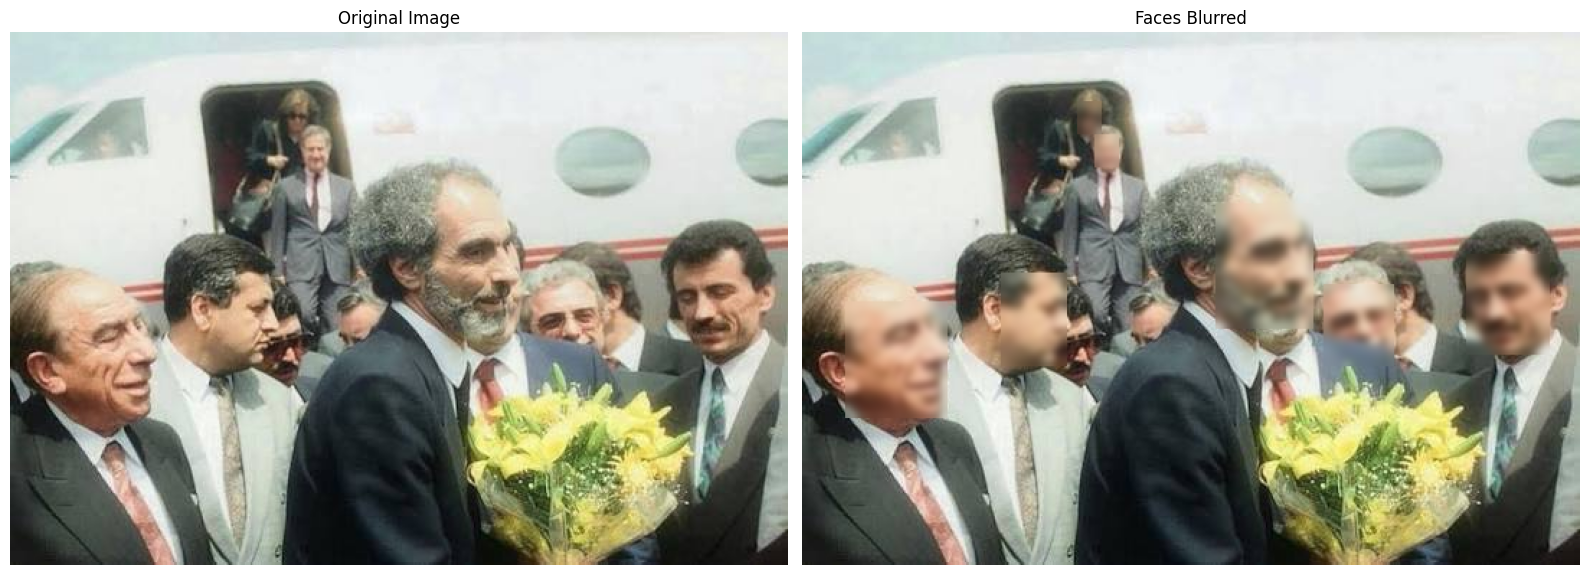

In [20]:
detector = cv2.FaceDetectorYN.create('model/face/face_detection_yunet_2023mar.onnx',
                                     "", (320, 320), 0.7, 0.3, 5000)

image_path = os.path.join('images', image_files[1])
image = cv2.imread(image_path)
assert image is not None, "Could not read image"

h, w = image.shape[:2]
detector.setInputSize((w, h))

result = detector.detect(image)
output = image.copy()

if result[1] is not None:
  print(f"Detected {len(result[1])} Face(s)")
  for face in result[1]:
    x, y, fw, fh = face[:4].astype(int)
    x = max(0, x)
    y = max(0, y)
    fw = min(fw, w - x)
    fh = min(fh, h - y)
    if fw <= 0 or fh <= 0:
      continue

    roi = output[y:y+fh, x:x+fw]
    k = max(15, (min(fw, fh) // 5) | 1)
    blurred = cv2.GaussianBlur(roi, (k, k), 0)
    output[y:y+fh, x:x+fw] = blurred

plt.figure(figsize=[16, 8])

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
plt.title("Faces Blurred")
plt.axis('off')

plt.tight_layout()
plt.show()

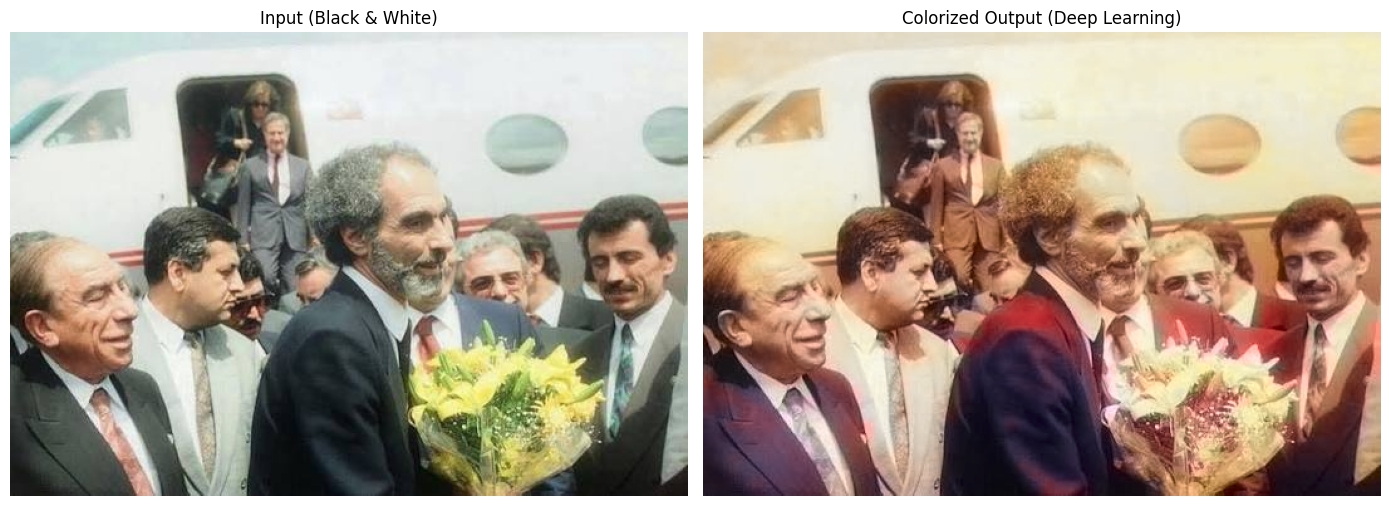

In [23]:
if not hasattr(cv2.dnn, 'readNetFromCaffe'):
    raise RuntimeError("Caffe Loader Not Found. Please Restart The Runtime After Running Cell 1.")

proto = 'model/colorization/colorization_deploy_v2.prototxt'
model = 'model/colorization/colorization_release_v2.caffemodel'
pts_path = 'model/colorization/pts_in_hull.npy'

net = cv2.dnn.readNetFromCaffe(proto, model)
pts = np.load(pts_path)

pts = pts.transpose().reshape(2, 313, 1, 1)
class8 = net.getLayerId("class8_ab")
conv8 = net.getLayerId("conv8_313_rh")
net.getLayer(class8).blobs = [pts.astype(np.float32)]
net.getLayer(conv8).blobs = [np.full([1, 313], 2.606, dtype=np.float32)]

bw_image_path = os.path.join('images', image_files[-1])
img = cv2.imread(bw_image_path)
assert img is not None, "Could Not Read Image"

if len(img.shape) == 2:
  img = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)

scaled = img.astype("float32") / 255.0
lab = cv2.cvtColor(scaled, cv2.COLOR_BGR2LAB)

resized = cv2.resize(lab, (224, 224))
L = cv2.split(resized)[0]
L -= 50

net.setInput(cv2.dnn.blobFromImage(L))
ab = net.forward()[0, :, :, :].transpose((1, 2, 0))

ab = cv2.resize(ab, (img.shape[1], img.shape[0]))
L_orig = cv2.split(lab)[0]

colorized = np.concatenate((L_orig[:, :, np.newaxis], ab), axis=2)
colorized = cv2.cvtColor(colorized, cv2.COLOR_LAB2BGR)
colorized = np.clip(colorized, 0, 1)
colorized = (255 * colorized).astype("uint8")

plt.figure(figsize=[14, 7])

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Input (Black & White)")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(colorized, cv2.COLOR_BGR2RGB))
plt.title("Colorized Output (Deep Learning)")
plt.axis('off')

plt.tight_layout()
plt.show()